# Verde Growth Model & Backtest
Executive simulation of customer unit economics, out-of-sample backtesting, and forward strategic scenarios.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# ==========================================
# CELL 1: GLOBAL CONTROL PANEL
# ==========================================
# Change these assumptions to instantly update the entire model
GROSS_PRODUCT_MARGIN = 0.55
OUTBOUND_SHIPPING_COST = 6.50

BASELINE_CAC_2025 = 15.30
H1_2026_BLENDED_CAC = 20.68
PEAK_META_CAC_2026 = 36.80

SCENARIO2_DAY0_MARGIN_LIFT = 2.10
SCENARIO3_DAY0_MARGIN = 18.68
SCENARIO3_REPEAT_RATE = 0.085


In [28]:
# ==========================================
# CELL 2: DATA INGESTION & PREPROCESSING
# ==========================================
orders = pd.read_csv('../data/cleaned/orders_cleaned.csv')
customers = pd.read_csv('../data/cleaned/customers_cleaned.csv')
marketing = pd.read_csv('../data/cleaned/marketing_cleaned.csv')

orders['order_date'] = pd.to_datetime(orders['order_date'])
customers['first_order_date'] = pd.to_datetime(customers['first_order_date'])
marketing['month'] = pd.to_datetime(marketing['month'])

orders['order_month'] = orders['order_date'].dt.to_period('M')
customers['cohort_month'] = customers['first_order_date'].dt.to_period('M')
marketing['spend_month'] = marketing['month'].dt.to_period('M')

# Apply Control Panel Variables to CM1 Calculation
orders['cm1'] = (GROSS_PRODUCT_MARGIN * orders['gross_product_eur'] - orders['discount_eur']) + (orders['shipping_fee_eur'] - OUTBOUND_SHIPPING_COST)

df = pd.merge(orders, customers[['customer_id', 'cohort_month']], on='customer_id', how='left')
df['cohort_age'] = (df['order_month'].dt.year - df['cohort_month'].dt.year) * 12 + (df['order_month'].dt.month - df['cohort_month'].dt.month)

print(f"Data successfully loaded. Processed {len(df)} orders across {len(customers)} customers.")


Data successfully loaded. Processed 38036 orders across 24123 customers.


In [29]:
# ==========================================
# CELL 3: LAYER 1 - CALIBRATION ENGINE (2025)
# ==========================================
c_2025_mask = customers['cohort_month'].astype(str).str.startswith('2025')
cust_2025_count = c_2025_mask.sum()
spend_2025 = marketing[marketing['spend_month'].astype(str).str.startswith('2025')]['spend_eur'].sum()
cac_2025 = spend_2025 / cust_2025_count

orders_2025 = df[df['cohort_month'].astype(str).str.startswith('2025')]
ltv_curve = orders_2025[orders_2025['cohort_age'] <= 12].groupby('cohort_age')['cm1'].sum().cumsum() / cust_2025_count

ret_rates = []
cohort_sizes = customers.groupby('cohort_month')['customer_id'].count()
mature_cohorts = [f"2025-{m:02d}" for m in range(1, 13)]
for age in range(1, 13):
    valid_c = [c for c in mature_cohorts if pd.Period(c, 'M') + age <= pd.Period('2025-12', 'M')]
    if valid_c:
        reps = df[(df['cohort_month'].astype(str).isin(valid_c)) & (df['cohort_age'] == age)]['order_id'].count()
        base = sum([cohort_sizes[pd.Period(c, 'M')] for c in valid_c])
        ret_rates.append(reps / base)
    else:
        ret_rates.append(ret_rates[-1])

print(f"2025 Calibration CAC: €{cac_2025:.2f} (Control panel default: €{BASELINE_CAC_2025:.2f})")
print(f"Day-0 Margin: €{ltv_curve[0]:.2f}")
print(f"Month 12 LTV: €{ltv_curve[12]:.2f}")


2025 Calibration CAC: €15.30 (Control panel default: €15.30)
Day-0 Margin: €14.59
Month 12 LTV: €26.37


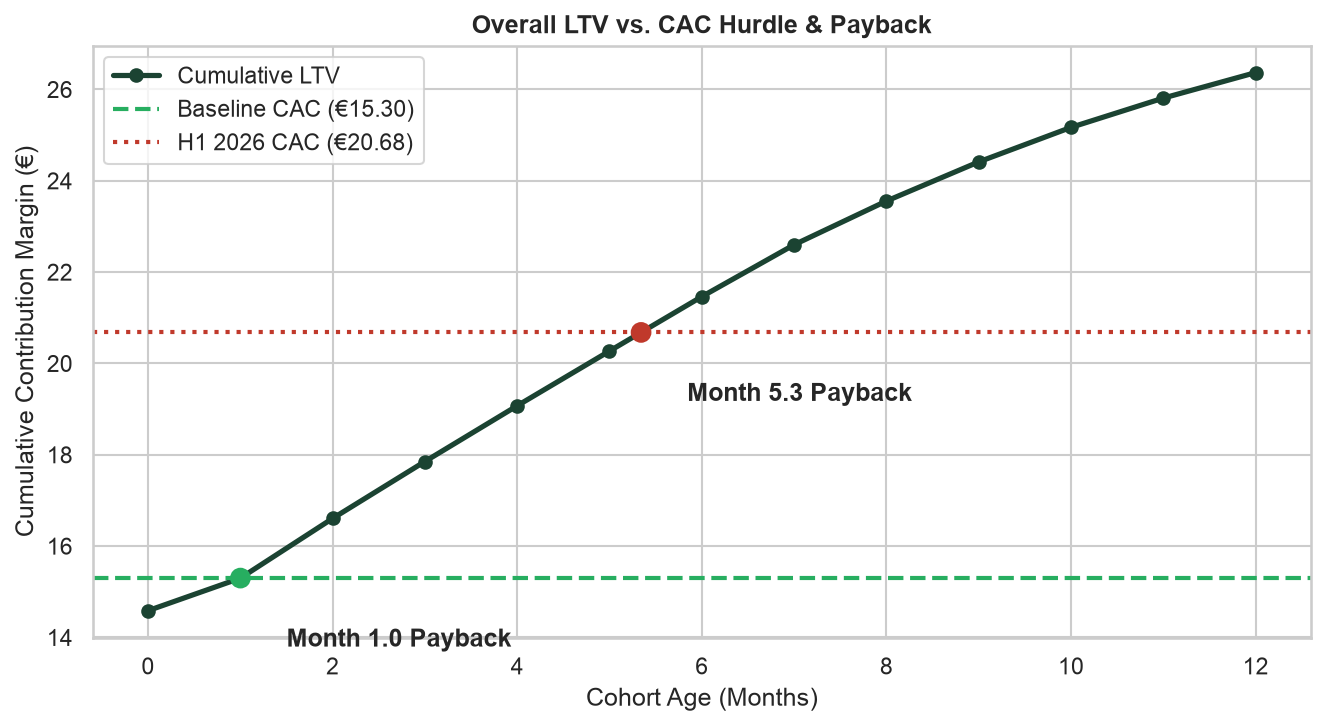

In [30]:
# ==========================================
# CELL 4: LAYER 2 - UNIT ECONOMICS VISUALIZATION
# ==========================================
plt.figure(figsize=(9, 5))
ages = ltv_curve.index
plt.plot(ages, ltv_curve.values, marker='o', color='#1b4332', lw=2.5, label='Cumulative LTV')
plt.axhline(BASELINE_CAC_2025, color='#27ae60', linestyle='--', lw=2, label=f'Baseline CAC (€{BASELINE_CAC_2025:.2f})')
plt.axhline(H1_2026_BLENDED_CAC, color='#c0392b', linestyle=':', lw=2, label=f'H1 2026 CAC (€{H1_2026_BLENDED_CAC:.2f})')

payback_2025 = np.interp(BASELINE_CAC_2025, ltv_curve.values, ages)
payback_2026 = np.interp(H1_2026_BLENDED_CAC, ltv_curve.values, ages)

plt.scatter([payback_2025, payback_2026], [BASELINE_CAC_2025, H1_2026_BLENDED_CAC], color=['#27ae60', '#c0392b'], s=80, zorder=5)
plt.annotate(f'Month {payback_2025:.1f} Payback', xy=(payback_2025, BASELINE_CAC_2025), xytext=(payback_2025+0.5, BASELINE_CAC_2025-1.5), fontweight='bold')
plt.annotate(f'Month {payback_2026:.1f} Payback', xy=(payback_2026, H1_2026_BLENDED_CAC), xytext=(payback_2026+0.5, H1_2026_BLENDED_CAC-1.5), fontweight='bold')

plt.title('Overall LTV vs. CAC Hurdle & Payback', fontweight='bold')
plt.xlabel('Cohort Age (Months)')
plt.ylabel('Cumulative Contribution Margin (€)')
plt.xticks(range(0, 13, 2))
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


In [31]:
# ==========================================
# CELL 5: LAYER 3 - BACKTEST ENGINE & DIAGNOSTICS
# ==========================================
h1_2026_str = [f"2026-0{m}" for m in range(1, 7)]
actuals = df[df['order_month'].astype(str).isin(h1_2026_str)].groupby('order_month').agg(
    actual_orders=('order_id', 'count'),
    actual_new=('cohort_age', lambda x: (x == 0).sum())
)
actuals['actual_repeat'] = actuals['actual_orders'] - actuals['actual_new']

pred_repeat, pred_new = [], []
for m_str in h1_2026_str:
    m_per = pd.Period(m_str, 'M')
    pr = sum(size * (ret_rates[((m_per.year - past_m.year)*12 + m_per.month - past_m.month)-1] if ((m_per.year - past_m.year)*12 + m_per.month - past_m.month) <= len(ret_rates) else 0.065) for past_m, size in cohort_sizes.items() if past_m < m_per)
    pred_repeat.append(pr)
    sp = marketing[marketing['spend_month'] == m_per]['spend_eur'].sum()
    pred_new.append(sp / BASELINE_CAC_2025)

pred_total = np.array(pred_repeat) + np.array(pred_new)
actual_rep_arr = actuals['actual_repeat'].values
actual_tot_arr = actuals['actual_orders'].values

mape_repeat = np.mean(np.abs(pred_repeat - actual_rep_arr) / actual_rep_arr) * 100
mape_total = np.mean(np.abs(pred_total - actual_tot_arr) / actual_tot_arr) * 100

print(f"Repeat Orders Prediction Error (MAPE): {mape_repeat:.2f}%")
print(f"Total Orders Prediction Error (MAPE): {mape_total:.2f}%")


Repeat Orders Prediction Error (MAPE): 2.36%
Total Orders Prediction Error (MAPE): 18.28%


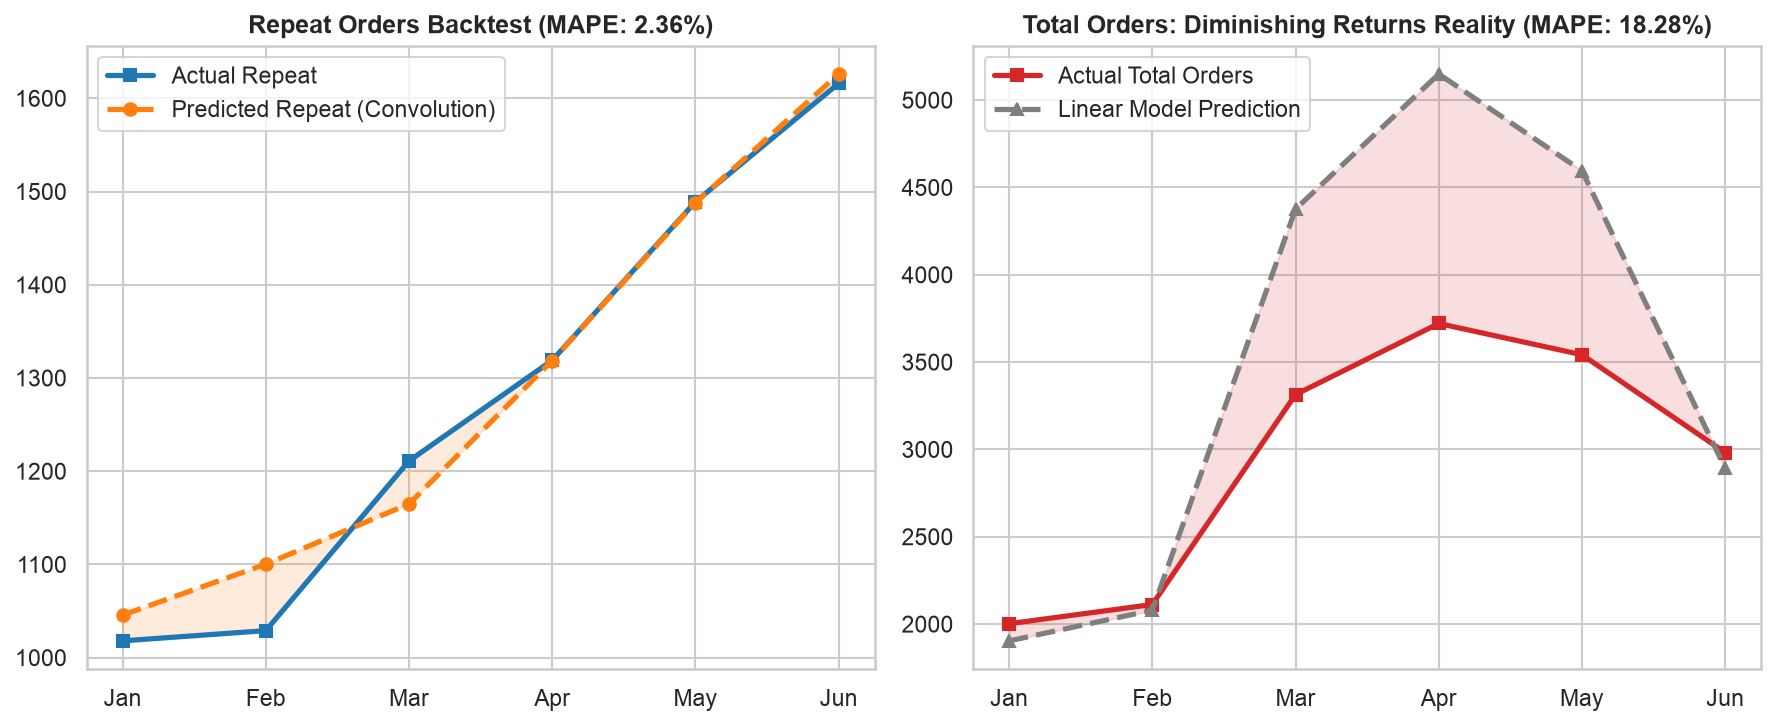

In [32]:
# ==========================================
# CELL 6: LAYER 3 - BACKTEST VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
x_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']

ax1.plot(x_labels, actual_rep_arr, marker='s', color='#1f77b4', lw=2.5, label='Actual Repeat')
ax1.plot(x_labels, pred_repeat, marker='o', color='#ff7f0e', ls='--', lw=2.5, label='Predicted Repeat (Convolution)')
ax1.fill_between(x_labels, actual_rep_arr, pred_repeat, color='#ff7f0e', alpha=0.15)
ax1.set_title(f'Repeat Orders Backtest (MAPE: {mape_repeat:.2f}%)', fontweight='bold')
ax1.legend()

ax2.plot(x_labels, actual_tot_arr, marker='s', color='#d62728', lw=2.5, label='Actual Total Orders')
ax2.plot(x_labels, pred_total, marker='^', color='#7f7f7f', ls='--', lw=2.5, label='Linear Model Prediction')
ax2.fill_between(x_labels, actual_tot_arr, pred_total, color='#d62728', alpha=0.15)
ax2.set_title(f'Total Orders: Diminishing Returns Reality (MAPE: {mape_total:.2f}%)', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()


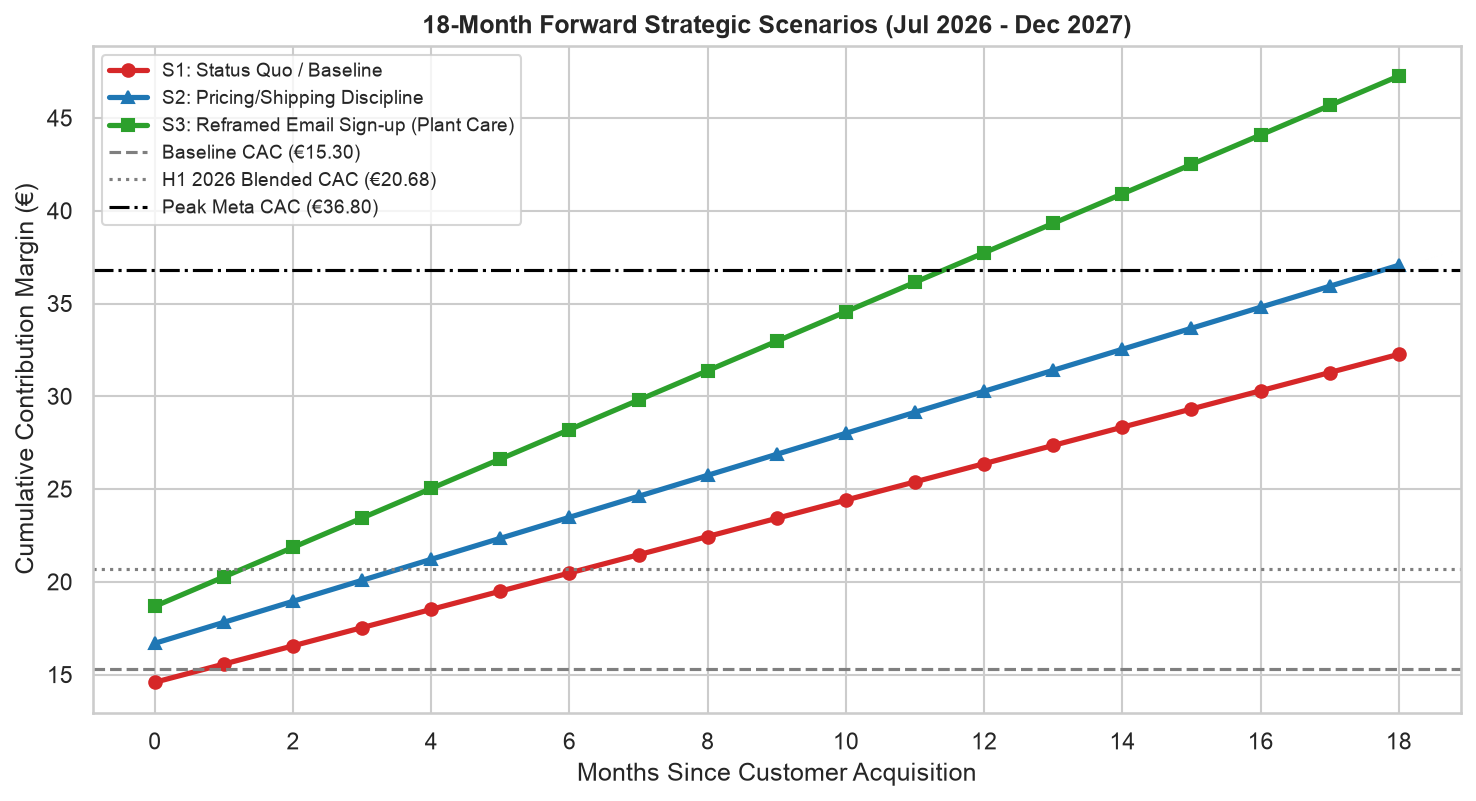

In [33]:
# ==========================================
# CELL 7: LAYER 4 - FORWARD SCENARIOS ENGINE & VISUALIZATION
# ==========================================
months_fwd = np.arange(19)

# Calculate base trajectories
cm_m0_base = ltv_curve[0]
cm_base_repeat = (ltv_curve[12] - ltv_curve[0]) / 12
s1_ltv = [cm_m0_base + cm_base_repeat * m for m in months_fwd]
s2_ltv = [(cm_m0_base + SCENARIO2_DAY0_MARGIN_LIFT) + (cm_base_repeat + 0.15) * m for m in months_fwd]

# Scenario 3 calculation using Control Panel variable for Day 0 & Repeat Rate
s3_ltv = [SCENARIO3_DAY0_MARGIN + (SCENARIO3_REPEAT_RATE * SCENARIO3_DAY0_MARGIN) * m for m in months_fwd]

plt.figure(figsize=(10, 5.5))
plt.plot(months_fwd, s1_ltv, marker='o', color='#d62728', lw=2.5, label='S1: Status Quo / Baseline')
plt.plot(months_fwd, s2_ltv, marker='^', color='#1f77b4', lw=2.5, label='S2: Pricing/Shipping Discipline')
plt.plot(months_fwd, s3_ltv, marker='s', color='#2ca02c', lw=2.5, label='S3: Reframed Email Sign-up (Plant Care)')

plt.axhline(BASELINE_CAC_2025, color='#7f7f7f', ls='--', label=f'Baseline CAC (€{BASELINE_CAC_2025:.2f})')
plt.axhline(H1_2026_BLENDED_CAC, color='#7f7f7f', ls=':', label=f'H1 2026 Blended CAC (€{H1_2026_BLENDED_CAC:.2f})')
plt.axhline(PEAK_META_CAC_2026, color='black', ls='-.', label=f'Peak Meta CAC (€{PEAK_META_CAC_2026:.2f})')

plt.title('18-Month Forward Strategic Scenarios (Jul 2026 - Dec 2027)', fontweight='bold')
plt.xlabel('Months Since Customer Acquisition')
plt.ylabel('Cumulative Contribution Margin (€)')
plt.xticks(range(0, 19, 2))
plt.legend(frameon=True, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()
